# Tutorial Class 07 Set 01

In [27]:
library(tidyverse)  # data manipulation and plotting
library(janitor)    # cleaning column names
library(recipes)    # For data preprocessing
library(cluster)    # clustering
library(factoextra) # k-means visualization and cluster evaluation
library(broom)      # tidy output of clustering results

In [28]:
df <-
  read_csv("../../../../data/hr_attrition.csv") |> 
  # tidy up column names to snake_case 
  clean_names()

Rows: 1470 Columns: 35
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (9): Attrition, BusinessTravel, Department, EducationField, Gender, Job...
dbl (26): Age, DailyRate, DistanceFromHome, Education, EmployeeCount, Employ...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Prepare these Exercises before Class

### Exercise 1

### Exercise 2

In [29]:
df_rule <- 
  df |>
  mutate(
    rule_segment = case_when(
      job_satisfaction >= 2 & distance_from_home < 10 ~ "Higher satisfaction, shorter commute",
      job_satisfaction >= 2 & distance_from_home >= 10 ~ "Higher satisfaction, longer commute",
      job_satisfaction < 2 & distance_from_home < 10 ~ "Lower satisfaction, shorter commute",
      .default = "Lower satisfaction, longer commute"
    )
  )

In [30]:
df_rule |>
  group_by(rule_segment) |>
  summarise(
    n_employees = n(),
    attrition_rate = mean(attrition == "Yes")
  )

rule_segment,n_employees,attrition_rate
<chr>,<int>,<dbl>
"Higher satisfaction, longer commute",426,0.1784038
"Higher satisfaction, shorter commute",755,0.1258278
"Lower satisfaction, longer commute",104,0.2692308
"Lower satisfaction, shorter commute",185,0.2054054


### Exercise 3

## In-Class Exercises

### Exercise 4

In [31]:
df_kmeans <- 
  df |>
  select(
    job_satisfaction,
    monthly_income,
    years_at_company,
    distance_from_home,
    age
  )

In [32]:
rec <- 
  recipe(~ ., data = df_kmeans) |>
  step_normalize(all_numeric_predictors())

In [33]:
df_scaled <- 
  rec |>
  prep() |>
  bake(new_data = NULL)

In [34]:
df_scaled |>
  summarise(
    across(
      everything(),
      list(mean = mean, sd = sd)
    )
  )

job_satisfaction_mean,job_satisfaction_sd,monthly_income_mean,monthly_income_sd,years_at_company_mean,years_at_company_sd,distance_from_home_mean,distance_from_home_sd,age_mean,age_sd
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
-1.260707e-16,1,-6.755745e-17,1,4.437116e-17,1,1.816385e-17,1,-2.514995e-17,1


### Exercise 5

In [35]:
df_scaled_small <-
  df_scaled |>
  select(job_satisfaction, distance_from_home)

In [36]:
set.seed(123)

kmeans_small <-
  kmeans(
    df_scaled_small,
    centers = 4,
    nstart = 10
  )

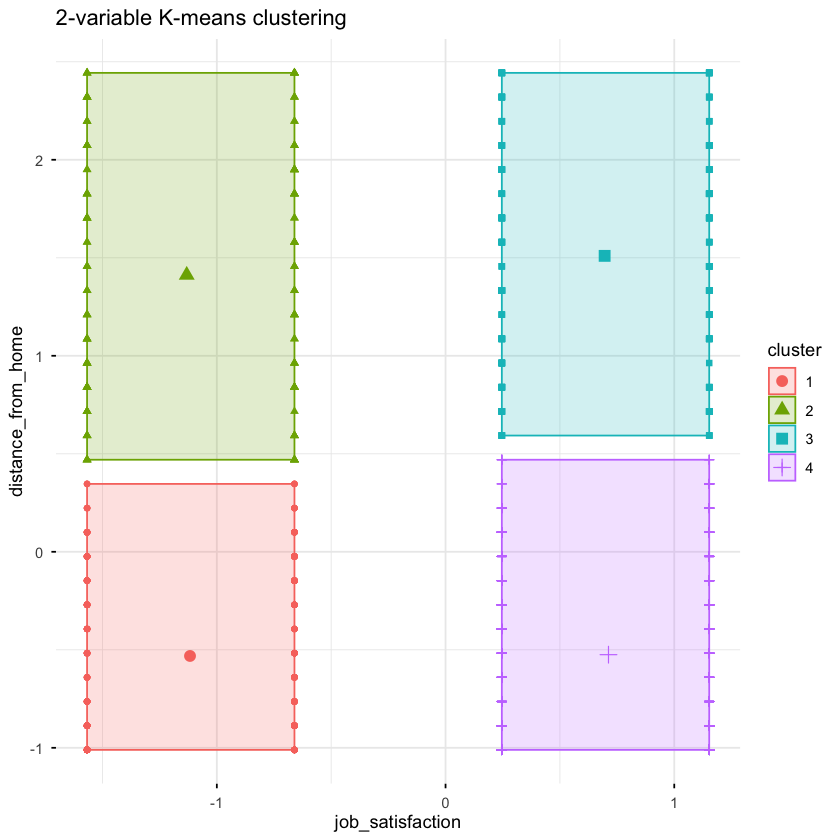

In [37]:
fviz_cluster(
  kmeans_small,
  data = df_scaled_small,
  geom = "point",
  ggtheme = theme_minimal(),
  main = "2-variable K-means clustering"
)

In [38]:
df_compare <-
  df |>
  select(attrition, job_satisfaction, distance_from_home) |>
  mutate(cluster = as.factor(kmeans_small$cluster))

df_compare |>
  group_by(cluster) |>
  summarise(
    n_employees    = n(),
    attrition_rate = mean(attrition == "Yes"),
    job_sat        = mean(job_satisfaction),
    distance       = mean(distance_from_home)
  )

cluster,n_employees,attrition_rate,job_sat,distance
<fct>,<int>,<dbl>,<dbl>,<dbl>
1,415,0.1710843,1.496386,4.884337
2,154,0.2662338,1.480519,20.636364
3,234,0.1709402,3.495726,21.431624
4,667,0.1274363,3.514243,4.937031


### Exercise 6

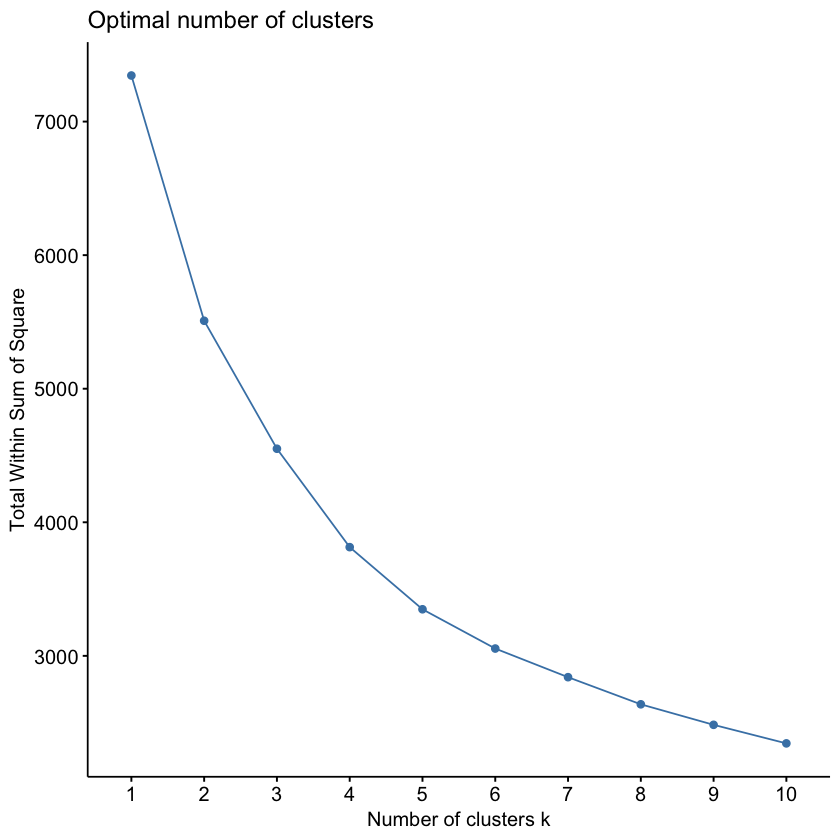

In [39]:
fviz_nbclust(
  df_scaled,
  kmeans,
  method = "wss",
  k.max = 10,
  nstart = 10
)

In [40]:
set.seed(123)

kmeans_full <-
  kmeans(
    df_scaled,
    centers = 4,
    nstart = 10
  )

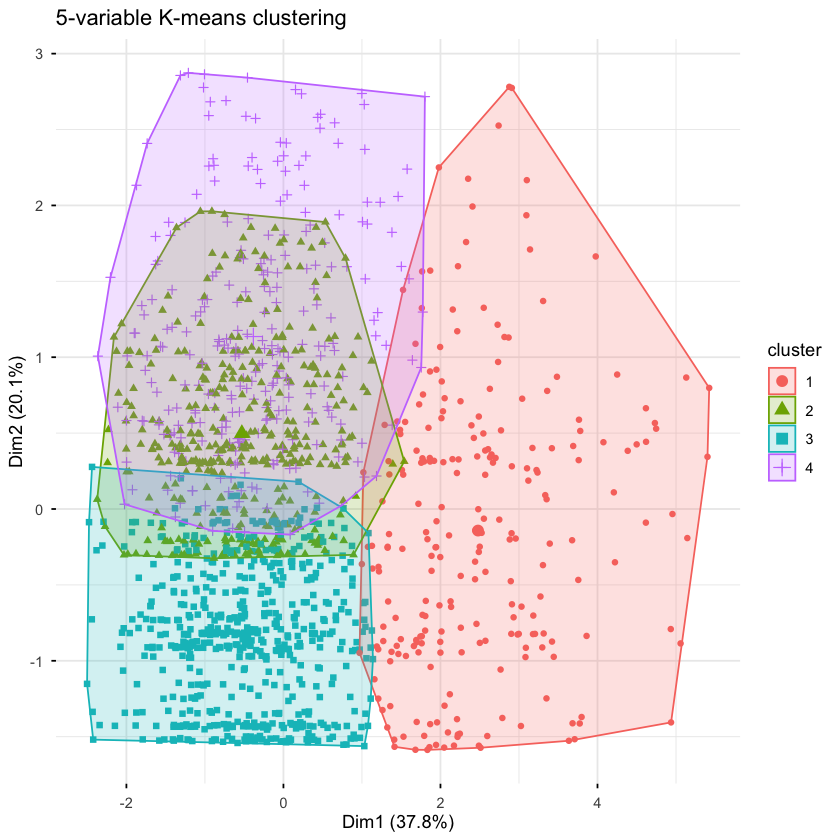

In [41]:
fviz_cluster(
  kmeans_full,
  data = df_scaled,
  geom = "point",
  ggtheme = theme_minimal(),
  main = "5-variable K-means clustering"
)

In [42]:
df_compare_full <-
  df |>
  select(
    attrition,
    job_satisfaction,
    monthly_income,
    years_at_company,
    distance_from_home,
    age
  ) |>
  mutate(cluster = as.factor(kmeans_full$cluster))

df_compare_full |>
  group_by(cluster) |>
  summarise(
    n_employees    = n(),
    attrition_rate = mean(attrition == "Yes"),
    job_sat        = mean(job_satisfaction),
    income         = mean(monthly_income),
    years          = mean(years_at_company),
    distance       = mean(distance_from_home),
    age            = mean(age)
  )

cluster,n_employees,attrition_rate,job_sat,income,years,distance,age
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,237,0.06751055,2.717300,14988.000,14.877637,7.662447,47.51477
2,387,0.19379845,1.457364,4669.447,5.348837,6.147287,34.42119
3,567,0.14285714,3.537919,4830.538,5.511464,5.372134,34.86420
4,279,0.23297491,2.856631,5237.140,5.666667,22.480287,35.58423
